In [1]:
import pandas as pd

df = pd.read_csv(r'..\data\W158_select_nan_recode.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [2]:
dep_var_list = [
    'CONF_a_W158_r',
    'CONF_b_W158_r',
    'CONF_c_W158_r',
    'CONF_d_W158_r',
    'CONF_e_W158_r',
    'CONF_i_W158_r',
    'CONF_j_W158_r'
    ]

print(dep_var_list)

['CONF_a_W158_r', 'CONF_b_W158_r', 'CONF_c_W158_r', 'CONF_d_W158_r', 'CONF_e_W158_r', 'CONF_i_W158_r', 'CONF_j_W158_r']


In [3]:
# Dependent variable labels
dep_labels = {
    'CONF_a_W158_r': 'Elected officials',
    'CONF_b_W158_r': 'Journalists',
    'CONF_c_W158_r': 'The military',
    'CONF_d_W158_r': 'Religious leaders',
    'CONF_e_W158_r': 'Business leaders',
    'CONF_i_W158_r': 'Public school principals',
    'CONF_j_W158_r': 'Police officers',
    }

print(dep_labels)

{'CONF_a_W158_r': 'Elected officials', 'CONF_b_W158_r': 'Journalists', 'CONF_c_W158_r': 'The military', 'CONF_d_W158_r': 'Religious leaders', 'CONF_e_W158_r': 'Business leaders', 'CONF_i_W158_r': 'Public school principals', 'CONF_j_W158_r': 'Police officers'}


In [7]:
# ---------------------------------------------------------
# Step 1: Impute Missing Data
# ---------------------------------------------------------
df_fa = df[dep_var_list].copy()

# Median imputation for 1-4 Likert/ordinal numeric scales
imputer = SimpleImputer(strategy="median")
df_imputed = pd.DataFrame(
    imputer.fit_transform(df_fa),
    columns=dep_var_list,
    index=df_fa.index
)

# ---------------------------------------------------------
# Step 2: Diagnostic Checks (Bartlett & KMO)
# ---------------------------------------------------------
# Calculate Correlation Matrix
corr_matrix = df_imputed.corr().values
n_obs, n_vars = df_imputed.shape

# Bartlett's Test of Sphericity
det_corr = np.linalg.det(corr_matrix)
statistic = -((n_obs - 1) - (2 * n_vars + 5) / 6) * np.log(det_corr)
deg_freedom = (n_vars * (n_vars - 1)) / 2
# p-value can be checked against scipy.stats.chi2.sf(statistic, deg_freedom)
print(f"Bartlett Test Statistic: {statistic:.3f} (df: {int(deg_freedom)})")

# Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy
inv_corr = np.linalg.inv(corr_matrix)
anti_image_cov = np.diag(1.0 / np.diag(inv_corr))
anti_image_corr = anti_image_cov @ inv_corr @ anti_image_cov
np.fill_diagonal(anti_image_corr, 0)

corr_sq = corr_matrix**2
np.fill_diagonal(corr_sq, 0)
anti_sq = anti_image_corr**2

kmo_overall = np.sum(corr_sq) / (np.sum(corr_sq) + np.sum(anti_sq))
print(f"Overall KMO Score: {kmo_overall:.3f}")

Bartlett Test Statistic: 14939.101 (df: 21)
Overall KMO Score: 0.859


In [8]:
df_imputed.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CONF_a_W158_r  9593 non-null   float64
 1   CONF_b_W158_r  9593 non-null   float64
 2   CONF_c_W158_r  9593 non-null   float64
 3   CONF_d_W158_r  9593 non-null   float64
 4   CONF_e_W158_r  9593 non-null   float64
 5   CONF_i_W158_r  9593 non-null   float64
 6   CONF_j_W158_r  9593 non-null   float64
dtypes: float64(7)
memory usage: 524.7 KB


In [11]:
df_imputed = df_imputed.rename(columns=dep_labels)
df_imputed.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Elected officials         9593 non-null   float64
 1   Journalists               9593 non-null   float64
 2   The military              9593 non-null   float64
 3   Religious leaders         9593 non-null   float64
 4   Business leaders          9593 non-null   float64
 5   Public school principals  9593 non-null   float64
 6   Police officers           9593 non-null   float64
dtypes: float64(7)
memory usage: 524.7 KB


In [12]:
import pandas as pd
from statsmodels.multivariate.factor import Factor

# -------------------------------------------------------------------
# Fit Factor Analysis via Maximum Likelihood or Principal Axis
# -------------------------------------------------------------------
# k_factor: Number of latent factors to extract (e.g., 2)
# method: 'ml' (maximum likelihood) or 'pa' (principal axis)
model = Factor(endog=df_imputed, n_factor=2, method='ml')
fit_res = model.fit()

# Summary output
print(fit_res.summary())

# Extract loadings
loadings_sm = pd.DataFrame(
    fit_res.loadings,
    index=df_imputed.columns,
    columns=[f"Factor_{i+1}" for i in range(2)]
)
print("\nStatsmodels Factor Loadings (Unrotated):")
print(loadings_sm.round(3))

                                                Factor analysis results
                                                                                                                       
-----------------------------------------------------------------------------------------------------------------------
                                    Communality                                                                        
-----------------------------------------------------------------------------------------------------------------------
 Elected officials Journalists The military Religious leaders Business leaders Public school principals Police officers
-----------------------------------------------------------------------------------------------------------------------
            0.3929      0.7063       0.4566            0.3526           0.3404                   0.3814          0.5469
----------------------------------------------------------------------------------------

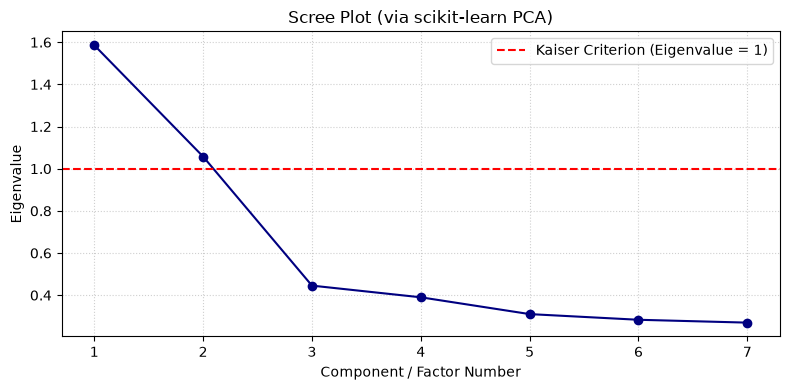

In [13]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Fit PCA on centered/scaled data to get eigenvalues
pca = PCA().fit(df_imputed)

# Eigenvalues correspond to explained variance of components
eigenvalues = pca.explained_variance_

# Scree Plot
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', color='navy')
plt.axhline(y=1, color='red', linestyle='--', label='Kaiser Criterion (Eigenvalue = 1)')
plt.title('Scree Plot (via scikit-learn PCA)')
plt.xlabel('Component / Factor Number')
plt.ylabel('Eigenvalue')
plt.xticks(range(1, len(eigenvalues) + 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import FactorAnalysis

# -------------------------------------------------------------------
# 1. Fit 3-Factor Model via scikit-learn
# -------------------------------------------------------------------
n_factors = 3
fa = FactorAnalysis(n_components=n_factors, random_state=42)
fa.fit(df_imputed)

# -------------------------------------------------------------------
# 2. Define Varimax Rotation Function
# -------------------------------------------------------------------
def varimax(Phi, max_iter=50, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0
    for _ in range(max_iter):
        d_old = d
        lambda_ = np.dot(Phi, R)
        u, s, vh = np.linalg.svd(
            np.dot(Phi.T, lambda_**3 - (1.0 / p) * np.dot(lambda_, np.diag(np.diag(np.dot(lambda_.T, lambda_))))))
        R = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and d / d_old < 1 + tol:
            break
    return np.dot(Phi, R)

# -------------------------------------------------------------------
# 3. Extract and Rotate Loadings
# -------------------------------------------------------------------
unrotated_loadings = fa.components_.T
rotated_matrix = varimax(unrotated_loadings)

# Convert to structured DataFrame
factor_names = ['Factor_1', 'Factor_2', 'Factor_3']
loadings_df = pd.DataFrame(
    rotated_matrix,
    index=df_imputed.columns,
    columns=factor_names
)

# -------------------------------------------------------------------
# 4. Variance Metrics Calculation
# -------------------------------------------------------------------
# Sum of Squared Loadings (SS Loadings)
ss_loadings = (loadings_df ** 2).sum(axis=0)
prop_variance = ss_loadings / len(df_imputed.columns)
cum_variance = prop_variance.cumsum()

variance_summary = pd.DataFrame([ss_loadings, prop_variance, cum_variance],
                                index=['SS Loadings', 'Proportion Var', 'Cumulative Var'],
                                columns=factor_names)

print("--- Variance Explained ---")
print(variance_summary.round(3))

print("\n--- Rotated Factor Loadings ---")
print(loadings_df.round(3))

--- Variance Explained ---
                Factor_1  Factor_2  Factor_3
SS Loadings        1.001     0.872     0.270
Proportion Var     0.143     0.125     0.039
Cumulative Var     0.143     0.268     0.306

--- Rotated Factor Loadings ---
                          Factor_1  Factor_2  Factor_3
Elected officials           -0.178     0.370     0.217
Journalists                  0.041     0.699     0.020
The military                -0.520     0.126     0.077
Religious leaders           -0.440    -0.015     0.251
Business leaders            -0.331     0.052     0.382
Public school principals    -0.178     0.477    -0.019
Police officers             -0.602    -0.018     0.085


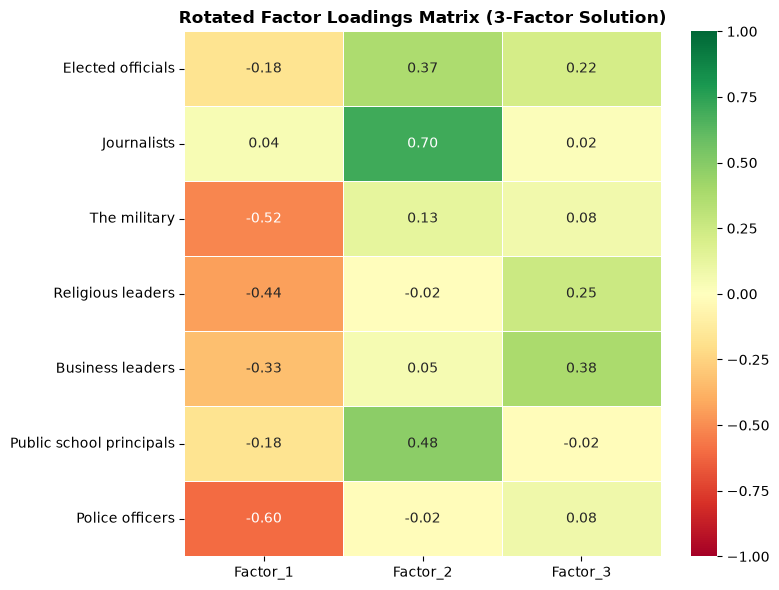

In [19]:
plt.figure(figsize=(8, 6))

# Threshold mask to highlight primary factor associations
sns.heatmap(
    loadings_df, 
    annot=True, 
    cmap='RdYlGn',
    center=0,
    fmt='.2f', 
    linewidths=0.5,
    vmin=-1, 
    vmax=1
)

plt.title('Rotated Factor Loadings Matrix (3-Factor Solution)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()